#### ML Model building and validation for SafeDrive Insurance Ltd.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

##### Loading the cleaned dataset

In [2]:
df = pd.read_csv("Cleaned_df.csv")

In [3]:
df.head()

,policy_tenure,age_of_car,age_of_policyholder,population_density,turning_radius,height,gross_weight,ncap_rating,Power_to_Weight_Ratio,is_esc,...,segment_B2,segment_C1,fuel_type_Diesel,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 Turbocharged Revotorq,engine_type_K Series Dual jet,engine_type_i-DTEC,High_Risk_Driver_Flag,is_claim
0,0.515874,0.05,0.644231,4990.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
1,0.672619,0.02,0.375000,27003.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
2,0.841110,0.02,0.384615,4076.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
3,0.900277,0.11,0.432692,21622.0,4.8,1515,1335,2,0.066292,1,...,0,1,0,0,1,0,0,0,0,0
4,0.596403,0.11,0.634615,34738.0,5.0,1490,1155,2,0.058061,0,...,0,0,0,0,0,0,0,0,0,0


#### Train-Test Split

In [4]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=['is_claim'])
y = df['is_claim']

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("\nTraining claim rate:", round(y_train.mean() * 100, 2), "%")
print("Testing claim rate:", round(y_test.mean() * 100, 2), "%")

X_train: (46873, 53)
X_test: (11719, 53)
y_train: (46873,)
y_test: (11719,)

Training claim rate: 6.4 %
Testing claim rate: 6.4 %


##### Scaling

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Identify binary columns (containing only 0 and 1)
binary_cols = [
    col for col in  X_train.columns
    if X_train[col].dropna().isin([0, 1]).all()
]

# Identify remaining numerical columns
num_cols = X_train.select_dtypes(include='number').columns.difference(
    binary_cols
).tolist()

# Build the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('binary', 'passthrough', binary_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
).set_output(transform='pandas')

X_train= preprocessor.fit_transform(X_train)   # fit on train only

In [6]:
X_train.head()

,Power_to_Weight_Ratio,age_of_car,age_of_policyholder,gross_weight,height,ncap_rating,policy_tenure,population_density,turning_radius,is_esc,...,segment_B1,segment_B2,segment_C1,fuel_type_Diesel,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 Turbocharged Revotorq,engine_type_K Series Dual jet,engine_type_i-DTEC,High_Risk_Driver_Flag
47135,0.650062,2.011600,0.013118,-0.237247,-0.482645,0.169917,-0.769378,1.107773,-0.233824,1,...,0,0,1,0,0,1,0,0,0,0
58128,-0.913279,0.379312,-1.087333,-0.213715,1.525594,0.169917,-0.527624,-0.828234,-0.672560,0,...,1,0,0,0,0,0,0,0,0,1
35000,0.650062,-0.708879,1.113569,-0.237247,-0.294373,0.169917,1.100508,-0.604848,-0.233824,0,...,0,1,0,0,0,0,0,1,0,0
6078,0.650062,0.197947,1.427984,-0.237247,-0.294373,0.169917,-0.022301,1.107773,-0.233824,0,...,0,1,0,0,0,0,0,1,0,0
34780,-1.401634,-1.071610,0.484740,-0.943200,-0.984705,-1.268762,0.525442,-0.828234,-1.111295,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
# Transform test data using the preprocessor fitted on X_train
X_test= preprocessor.transform(X_test)

print("Transformed test data shape:", X_test.shape)
print("Transformed train data shape:", X_train.shape)

Transformed test data shape: (11719, 53)
Transformed train data shape: (46873, 53)


##### Independence of observations check

In [8]:
# Check dataset dimensions
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

# Check duplicate rows
print("Duplicate training rows:", X_train.duplicated().sum())

Training rows: 46873
Testing rows: 11719
Duplicate training rows: 0


##### Linearity of log-odds assumption

In [9]:
from statsmodels.nonparametric.smoothers_lowess import lowess

continuous_features = [
    "policy_tenure", "age_of_car", "age_of_policyholder", "population_density",
    "height", "gross_weight", "ncap_rating", "Power_to_Weight_Ratio"
]

X_check = X_train[continuous_features].copy()

# Preserve row alignment with X
if isinstance(y_train, pd.Series):
    y_check = y_train.loc[X_check.index]
else:
    y_check = pd.Series(
        np.asarray(y_train).ravel(),
        index=X_check.index
    )

for col in continuous_features:
    temp = pd.DataFrame({
        "feature": X_check[col],
        "claim": y_check
    }).dropna()

    # Ten quantile-based bins
    temp["bin"] = pd.qcut(
        temp["feature"],
        q=10,
        duplicates="drop"
    )

    summary = temp.groupby(
        "bin", observed=True
    ).agg(
        mean_x=("feature", "mean"),
        claims=("claim", "sum"),
        total=("claim", "count")
    )

    # Empirical log-odds with continuity correction
    summary["log_odds"] = np.log(
        (summary["claims"] + 0.5) /
        (summary["total"] - summary["claims"] + 0.5)
    )

    summary = summary.sort_values("mean_x")

    plt.figure(figsize=(8, 5))

    plt.scatter(
        summary["mean_x"],
        summary["log_odds"],
        label="Decile log-odds"
    )

    # Smooth trend, when enough distinct points are available
    if len(summary) >= 4:
        smooth = lowess(
            summary["log_odds"],
            summary["mean_x"],
            frac=0.6,
            return_sorted=True
        )

        plt.plot(
            smooth[:, 0],
            smooth[:, 1],
            color="red",
            label="LOWESS trend"
        )

    plt.xlabel(col)
    plt.ylabel("Empirical log-odds of claim")
    plt.title(f"Linearity of Log-Odds: {col}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"\n{col}:")
    print(summary[["mean_x", "claims", "total", "log_odds"]])


<Figure size 800x500 with 1 Axes>


policy_tenure:
                                 mean_x  claims  total  log_odds
bin                                                             
(-1.4709999999999999, -1.279] -1.370911     187   4688 -3.178387
(-1.279, -1.14]               -1.234801     148   4687 -3.419987
(-1.14, -0.821]               -0.975967     197   4687 -3.123981
(-0.821, -0.45]               -0.649861     234   4687 -2.943990
(-0.45, -0.089]               -0.254203     282   4688 -2.747157
(-0.089, 0.398]                0.134318     331   4687 -2.575796
(0.398, 0.946]                 0.671171     425   4687 -2.304346
(0.946, 1.123]                 1.032953     396   4687 -2.381716
(1.123, 1.322]                 1.218463     402   4687 -2.365297
(1.322, 1.891]                 1.428879     396   4688 -2.381949


<Figure size 800x500 with 1 Axes>


age_of_car:
                                 mean_x  claims  total  log_odds
bin                                                             
(-1.2539999999999998, -1.072] -1.153228     673   9264 -2.546041
(-1.072, -0.89]               -0.890244     256   4133 -2.715817
(-0.89, -0.709]               -0.708879     223   3565 -2.705063
(-0.709, -0.528]              -0.527514     198   3036 -2.660242
(-0.528, -0.165]              -0.259171     338   5115 -2.647149
(-0.165, 0.198]                0.104937     311   4520 -2.603700
(0.198, 0.561]                 0.476877     315   4638 -2.617662
(0.561, 0.923]                 0.833422     246   3904 -2.697447
(0.923, 1.468]                 1.276002     278   5153 -2.862560
(1.468, 3.19]                  2.059870     160   3545 -3.048963


<Figure size 800x500 with 1 Axes>


age_of_policyholder:
                                 mean_x  claims  total  log_odds
bin                                                             
(-1.4809999999999999, -1.245] -1.358442     274   4839 -2.811332
(-1.245, -0.93]               -1.047678     303   5443 -2.829524
(-0.93, -0.694]               -0.775834     239   4098 -2.779740
(-0.694, -0.38]               -0.500235     332   5355 -2.715242
(-0.38, -0.144]               -0.224194     280   4033 -2.593870
(-0.144, 0.17]                 0.050258     364   5291 -2.604060
(0.17, 0.485]                  0.361608     318   4775 -2.638721
(0.485, 0.799]                 0.674382     235   3749 -2.702942
(0.799, 1.428]                 1.126634     310   4723 -2.654239
(1.428, 2.882]                 2.013656     343   4567 -2.509469


... (6 outputs left out)

<Figure size 800x500 with 1 Axes>


ncap_rating:
                               mean_x  claims  total  log_odds
bin                                                           
(-1.2699999999999998, 0.17] -0.507035    2077  32363 -2.679537
(0.17, 0.889]                0.889257     707  11214 -2.698107
(0.889, 2.328]               1.952989     214   3296 -2.665186


<Figure size 800x500 with 1 Axes>


Power_to_Weight_Ratio:
                                 mean_x  claims  total  log_odds
bin                                                             
(-1.4029999999999998, -0.913] -1.275032     987  16199 -2.734696
(-0.913, 0.223]                0.164934     197   3190 -2.718460
(0.223, 0.629]                 0.593487     867  13578 -2.684647
(0.629, 0.65]                  0.650062     829  11893 -2.590674
(0.65, 2.359]                  2.155260     118   2013 -2.772325


### Linearity of Log-Odds Results
- **Policy tenure:** Log-odds generally increase with policy tenure, with a slight decline in the higher bins.
- **Age of car:** Log-odds initially remain relatively stable, then decrease for older cars, indicating a nonlinear pattern.
- **Age of policyholder:** Log-odds fluctuate slightly but show a generally weak upward trend.
- Other features show irregular fluctuations without a clear linear trend.
- **Conclusion:** The plots suggest potential nonlinearity, particularly for policy tenure and age of car; further validation needs to be done before finalizing the logistic regression model.

In [10]:
X_train.columns

Index(['Power_to_Weight_Ratio', 'age_of_car', 'age_of_policyholder',
       'gross_weight', 'height', 'ncap_rating', 'policy_tenure',
       'population_density', 'turning_radius', 'is_esc',
       'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'is_brake_assist', 'is_power_door_locks',
       'is_day_night_rear_view_mirror', 'is_speed_alert', 'airbags_1',
       'airbags_2', 'area_cluster_C1', 'area_cluster_C10', 'area_cluster_C11',
       'area_cluster_C12', 'area_cluster_C13', 'area_cluster_C14',
       'area_cluster_C15', 'area_cluster_C16', 'area_cluster_C17',
       'area_cluster_C18', 'area_cluster_C19', 'area_cluster_C2',
       'area_cluster_C20', 'area_cluster_C21', 'area_cluster_C22',
       'area_cluster_C3', 'area_cluster_C4', 'area_cluster_C5',
       'area_cluster_C6', 'area_cluster_C7', 'area_cluster_C8',
       'area_cluster_C9', 'segment_A', 'segment_B1', 'segment_B2',
       'segment_C1', 'fuel_type_Diesel', 'engine_type_1.2 L K

#### Model Building

- Train the Logistic Regression model

In [11]:
from sklearn.linear_model import LogisticRegression

# Create the model
baseline_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Train the model
baseline_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Predictions

In [12]:
# 2. Predict on the test set
y_train_pred = baseline_model.predict(X_train)
y_test_pred = baseline_model.predict(X_test)
y_test_pred_proba = baseline_model.predict_proba(X_test)[:, 1]
y_train_pred_proba = baseline_model.predict_proba(X_train)[:, 1]

#### Evaluation

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred, zero_division=0)
recall = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)
auc = roc_auc_score(y_test, y_test_pred_proba)

train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred, zero_division=0)
train_recall = recall_score(y_train, y_train_pred, zero_division=0)
train_f1 = f1_score(y_train, y_train_pred, zero_division=0)
train_auc = roc_auc_score(y_train, y_train_pred_proba)

In [14]:
# Print results
print("\n--- Baseline Logistic Regression: Train Results ---")
print(f"Accuracy  : {train_accuracy:.4f}")
print(f"Precision : {train_precision:.4f}")
print(f"Recall    : {train_recall:.4f}")
print(f"F1-Score  : {train_f1:.4f}")
print(f"ROC-AUC   : {train_auc:.4f}")


--- Baseline Logistic Regression: Train Results ---
Accuracy  : 0.5676
Precision : 0.0868
Recall    : 0.6054
F1-Score  : 0.1519
ROC-AUC   : 0.6200


In [15]:
# Print results
print("\n--- Baseline Logistic Regression: Test Results ---")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")


--- Baseline Logistic Regression: Test Results ---
Accuracy  : 0.5693
Precision : 0.0803
Recall    : 0.5480
F1-Score  : 0.1401
ROC-AUC   : 0.5853


In [16]:
y_test_pred_proba

array([0.57280722, 0.32651223, 0.42789146, ..., 0.49730012, 0.57521171,
       0.68386443])

##### ROC curve for the test set

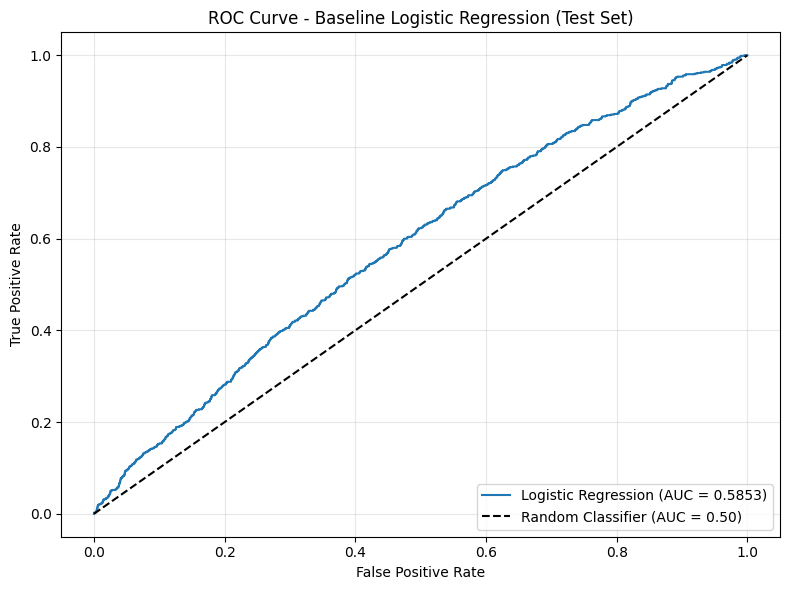

In [17]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {train_auc if False else roc_auc_score(y_test, y_test_pred_proba):.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier (AUC = 0.50)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Baseline Logistic Regression (Test Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


##### Five-fold stratified cross-validation 

In [18]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    clone(baseline_model),
    X_train,
    y_train,
    cv=skf,
    scoring={"roc_auc": "roc_auc", "f1": "f1"},
    n_jobs=-1
)

print("5-Fold Stratified Cross-Validation Results")
print(f"ROC-AUC: {cv_results['test_roc_auc'].mean():.4f} ± "
      f"{cv_results['test_roc_auc'].std():.4f}")
print(f"F1-Score: {cv_results['test_f1'].mean():.4f} ± "
      f"{cv_results['test_f1'].std():.4f}")


5-Fold Stratified Cross-Validation Results
ROC-AUC: 0.6101 ± 0.0062
F1-Score: 0.1499 ± 0.0028


##### coefficient and odds-ratio table

In [19]:
coef_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": baseline_model.coef_[0]
})

coef_table["Odds_Ratio"] = np.exp(coef_table["Coefficient"])
coef_table["Direction"] = np.where(
    coef_table["Coefficient"] > 0,
    "Positive",
    np.where(coef_table["Coefficient"] < 0, "Negative", "Neutral")
)

coef_table["Abs_Coefficient"] = coef_table["Coefficient"].abs()

coef_table = (
    coef_table.sort_values("Abs_Coefficient", ascending=False)
    .drop(columns="Abs_Coefficient")
    .reset_index(drop=True)
)

display(coef_table.round(4))


,Feature,Coefficient,Odds_Ratio,Direction
0,area_cluster_C18,0.8184,2.2668,Positive
1,area_cluster_C17,-0.4689,0.6257,Negative
2,area_cluster_C21,0.4023,1.4953,Positive
3,policy_tenure,0.3824,1.4658,Positive
4,area_cluster_C4,0.3111,1.3650,Positive
5,area_cluster_C7,-0.2825,0.7539,Negative
6,area_cluster_C15,-0.2662,0.7663,Negative
7,area_cluster_C16,-0.2487,0.7798,Negative
8,area_cluster_C11,-0.2365,0.7894,Negative
9,area_cluster_C3,0.2007,1.2223,Positive


#### Baseline Logistic Regression – Results

- The model achieved **56.93% test accuracy** and a **ROC-AUC of 0.5853**, indicating weak classification and limited ability to distinguish between claim and non-claim policies.
- Test precision is low at **8.03%**, meaning that only about 8% of the policies predicted as claims were actual claims.
- Test recall is **54.80%**, indicating that the model identifies approximately 55% of actual claims.
- The similar train and test metrics suggest **limited overfitting**, although the model's overall predictive performance remains weak.
- Further improvements through feature engineering, class-imbalance handling, and decision-threshold tuning may help improve claim detection.

#### Cross-Validation and Feature Interpretation

- **5-fold stratified cross-validation** achieved a mean ROC-AUC of **0.6101 ± 0.0062** and a mean F1-score of **0.1499 ± 0.0028**, indicating relatively consistent but limited predictive performance across folds.
- `area_cluster_C18` has the largest positive coefficient (0.8184; odds ratio 2.2668), while `area_cluster_C17` has the largest negative coefficient (-0.4689; odds ratio 0.6257).
- `policy_tenure` shows a positive association with claim odds, whereas `age_of_car` shows a negative association, holding other features constant.
- Several features have coefficients close to zero, suggesting smaller individual effects on the log-odds scale, although their importance also depends on feature scaling and the values they take.
- Overall, the baseline model provides a useful benchmark for comparison with more advanced models. However, its low precision and F1-score indicate that further improvements are needed to identify claims more effectively.

#### Summary of Baseline Logistic Regression Findings

##### 1. Key Predictors

The most influential predictors based on absolute coefficient magnitude include `area_cluster_C18`, `area_cluster_C17`, `area_cluster_C21`, `policy_tenure`, and `area_cluster_C4`. Vehicle-related features such as `age_of_car` and `is_adjustable_steering` also contribute to the model's predictions.

##### 2. Feature Impacts

- **Positive association:** `area_cluster_C18` has a coefficient of **0.8184** and an odds ratio of **2.2668**, indicating approximately 2.27 times the claim odds relative to the reference area cluster, holding other features constant.
- **Negative association:** `area_cluster_C17` has a coefficient of **-0.4689** and an odds ratio of **0.6257**, corresponding to approximately **37.4% lower claim odds** relative to the reference area cluster.
- **Policy tenure:** Its coefficient of **0.3824** and odds ratio of **1.4658** indicate approximately **46.6% higher estimated claim odds** for a one-unit increase, assuming the feature is measured in its original units.
- **Vehicle age:** Its coefficient of **-0.1950** and odds ratio of **0.8228** indicate approximately **17.7% lower estimated claim odds** for a one-unit increase, holding other features constant.

These results describe model associations, not causal relationships. Categorical feature effects are relative to their omitted reference categories.

##### 3. Strengths

- Logistic regression is interpretable, allowing feature effects to be examined using coefficients and odds ratios.
- Five-fold stratified cross-validation produced a mean ROC-AUC of **0.6101 ± 0.0062** and F1-score of **0.1499 ± 0.0028**, indicating relatively consistent performance across folds.
- Similar training and test metrics suggest limited evidence of severe overfitting.

##### 4. Weaknesses

- Test ROC-AUC of **0.5853** indicates weak discrimination between claim and non-claim cases.
- Test precision of **8.03%** is low, meaning many policies predicted as claims are false positives.
- Test F1-score of **0.1401** indicates limited overall performance when balancing precision and recall.
- The model may not capture nonlinear relationships or complex interactions between predictors.

##### 5. Areas for Improvement

- Evaluate alternative classification thresholds to improve the precision-recall trade-off.
- Compare logistic regression with tree-based models such as Random Forest, XGBoost, or LightGBM.
- Investigate additional feature engineering, nonlinear relationships, and meaningful feature interactions.
- Handle class imbalance carefully and compare approaches using stratified cross-validation.
- Compare models using ROC-AUC, precision, recall, F1-score, and the precision-recall curve, with particular attention to the business cost of missed claims versus false alarms.

##### Overall Conclusion

The baseline logistic regression provides an interpretable starting point, but its predictive performance is limited, particularly in precision and overall claim discrimination. Further model development and threshold evaluation are needed before considering it suitable for operational claim prediction.

#### Rebuilding the identical train-test split

In [20]:
target_col = "is_claim"

X = df.drop(columns=[target_col])
y = df[target_col]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
assert X_train2.index.equals(X_train.index), \
    "Training indices do not match!"

print("Both training sets have identical indices.")

Both training sets have identical indices.


In [22]:
# Check the shapes
print("X_train:", X_train2.shape)
print("X_test:", X_test2.shape)
print("y_train:", y_train2.shape)
print("y_test:", y_test2.shape)
print("\nTraining claim rate:", round(y_train2.mean() * 100, 2), "%")
print("Testing claim rate:", round(y_test2.mean() * 100, 2), "%")

X_train: (46873, 53)
X_test: (11719, 53)
y_train: (46873,)
y_test: (11719,)

Training claim rate: 6.4 %
Testing claim rate: 6.4 %


In [23]:
# Identify binary columns (containing only 0 and 1)
binary_cols = [
    col for col in  X_train2.columns
    if X_train2[col].dropna().isin([0, 1]).all()
]

# Identify remaining numerical columns
num_cols = X_train2.select_dtypes(include='number').columns.difference(
    binary_cols
).tolist()

# Build the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('binary', 'passthrough', binary_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
).set_output(transform='pandas')

X_train2= preprocessor.fit_transform(X_train2)   # fit on train only

In [24]:
# Transform test data using the preprocessor fitted on X_train
X_test2= preprocessor.transform(X_test2)

print("Transformed test data shape:", X_test2.shape)
print("Transformed train data shape:", X_train2.shape)

Transformed test data shape: (11719, 53)
Transformed train data shape: (46873, 53)


#### Optuna-tuned Decision Tree

In [25]:
import optuna

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from optuna.samplers import TPESampler

# 1. Define 3-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 2. Define the Optuna objective function
def objective(trial):

    max_depth = trial.suggest_int("max_depth", 3, 15)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 50)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 30)

    model = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        class_weight="balanced",
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train2,
        y_train2,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    return scores.mean()

# 3. Create the Optuna study
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42)
)

# 4. Run 25 trials
study.optimize(objective, n_trials=25)

# 5. Display the best results
print("Best trial ROC-AUC:", study.best_trial.value)
print("Best hyperparameters:", study.best_params)

[I 2026-10-27 17:20:31,909] A new study created in memory with name: no-name-352cc812-5a1d-412d-b37a-909f240c04c4
[I 2026-10-27 17:20:35,177] Trial 0 finished with value: 0.6155640161072754 and parameters: {'max_depth': 7, 'min_samples_split': 48, 'min_samples_leaf': 22}. Best is trial 0 with value: 0.6155640161072754.
[I 2026-10-27 17:20:35,838] Trial 1 finished with value: 0.5899900977558755 and parameters: {'max_depth': 10, 'min_samples_split': 9, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.6155640161072754.
[I 2026-10-27 17:20:37,243] Trial 2 finished with value: 0.6293102684678981 and parameters: {'max_depth': 3, 'min_samples_split': 44, 'min_samples_leaf': 19}. Best is trial 2 with value: 0.6293102684678981.
[I 2026-10-27 17:20:37,809] Trial 3 finished with value: 0.5837579289260771 and parameters: {'max_depth': 12, 'min_samples_split': 3, 'min_samples_leaf': 30}. Best is trial 2 with value: 0.6293102684678981.
[I 2026-10-27 17:20:38,617] Trial 4 finished with value: 0.

Best trial ROC-AUC: 0.6338709178123993
Best hyperparameters: {'max_depth': 4, 'min_samples_split': 17, 'min_samples_leaf': 1}


##### Creating the tuned Decision Tree

In [26]:
from sklearn.tree import DecisionTreeClassifier

best_tree = DecisionTreeClassifier(
    **study.best_params,
    class_weight="balanced",
    random_state=42
)

##### Run 5-fold CV for both models

In [27]:
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1"
}

# Logistic Regression
lr_cv = cross_validate(
    baseline_model, X_train, y_train,
    cv=cv5, scoring=scoring, n_jobs=-1
)

# Optuna-tuned Decision Tree
tree_cv = cross_validate(
    best_tree, X_train2, y_train2,
    cv=cv5, scoring=scoring, n_jobs=-1
)

##### Evaluating both models on the test sets

In [28]:
# Fit models on full training sets
baseline_model.fit(X_train, y_train)
best_tree.fit(X_train2, y_train2)

# Predictions
lr_pred = baseline_model.predict(X_test)
lr_prob = baseline_model.predict_proba(X_test)[:, 1]

tree_pred = best_tree.predict(X_test2)
tree_prob = best_tree.predict_proba(X_test2)[:, 1]


def test_metrics(y_true, pred, prob):
    return {
        "Test Accuracy": accuracy_score(y_true, pred),
        "Test Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_true, pred, zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(y_true, prob)
    }

lr_metrics = test_metrics(y_test, lr_pred, lr_prob)
tree_metrics = test_metrics(y_test2, tree_pred, tree_prob)

##### Building the comparison DataFrame

In [29]:
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        **lr_metrics,
        "CV ROC-AUC Mean": lr_cv["test_roc_auc"].mean(),
        "CV ROC-AUC Std": lr_cv["test_roc_auc"].std(),
        "CV F1 Mean": lr_cv["test_f1"].mean(),
        "CV F1 Std": lr_cv["test_f1"].std()
    },
    {
        "Model": "Optuna-Tuned Decision Tree",
        **tree_metrics,
        "CV ROC-AUC Mean": tree_cv["test_roc_auc"].mean(),
        "CV ROC-AUC Std": tree_cv["test_roc_auc"].std(),
        "CV F1 Mean": tree_cv["test_f1"].mean(),
        "CV F1 Std": tree_cv["test_f1"].std()
    }
]).set_index("Model").round(4)

comparison_df

,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,CV ROC-AUC Mean,CV ROC-AUC Std,CV F1 Mean,CV F1 Std
Model,,,,,,,,,
Logistic Regression,0.5693,0.0803,0.5480,0.1401,0.5853,0.6101,0.0062,0.1499,0.0028
Optuna-Tuned Decision Tree,0.5513,0.0893,0.6533,0.1571,0.6458,0.6399,0.0131,0.1586,0.0053


##### Model Comparison and Findings

The Optuna-Tuned Decision Tree outperformed Logistic Regression in test ROC-AUC (0.6458 vs. 0.5853), F1-score (0.1571 vs. 0.1401), and recall (0.6533 vs. 0.5480). However, both models have low precision, indicating a high number of false-positive claim predictions. The results suggest that the Decision Tree has better discrimination ability, but its predictive performance remains limited. Further improvements could include testing ensemble models, reviewing feature quality, and tuning the classification threshold according to the business objective.

In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

tree_prob = best_tree.predict_proba(X_test2)[:, 1]

for threshold in [0.3, 0.4, 0.5]:
    pred = (tree_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test2, pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test2, pred, zero_division=0), 4))
    print("F1:", round(f1_score(y_test2, pred, zero_division=0), 4))


Threshold: 0.3
Precision: 0.0716
Recall: 0.96
F1: 0.1332

Threshold: 0.4
Precision: 0.0822
Recall: 0.832
F1: 0.1496

Threshold: 0.5
Precision: 0.0893
Recall: 0.6533
F1: 0.1571


##### The model with higher test ROC-AUC

In [31]:
selected_model = comparison_df["Test ROC-AUC"].idxmax()

print("Selected model:", selected_model)
print(
    "Test ROC-AUC:",
    comparison_df.loc[selected_model, "Test ROC-AUC"]
)

Selected model: Optuna-Tuned Decision Tree
Test ROC-AUC: 0.6458


##### Define the Output Directory

Create a dedicated `mlflow_outputs` folder to store MLflow tracking files, exported experiment results, and model artifacts. The folder is created automatically if it does not already exist.

In [32]:
from pathlib import Path

# Folder for MLflow outputs
OUT_DIR = Path.cwd() / "mlflow_outputs"

# Create the folder if it does not exist
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUT_DIR.resolve())

Output directory: C:\Users\kanwa\Downloads\capstone\mlflow_outputs


##### Set the version and save the model using joblib

In [33]:
import os
os.environ["GIT_PYTHON_REFRESH"] = "quiet"

import mlflow

In [34]:
import json
import joblib

from datetime import datetime, timezone

# Select the fitted winning model
if selected_model == "Optuna-Tuned Decision Tree":
    chosen_model = best_tree
    model_name = "Optuna-Tuned Decision Tree"
    X_train_chosen = X_train2
    y_train_chosen = y_train2
    y_test_chosen = y_test2
    metric_summary = tree_metrics.copy()
    mlflow_run_name = "Optuna_Tuned_Decision_Tree"

else:
    chosen_model = baseline_model
    model_name = "Logistic Regression"
    X_train_chosen = X_train
    y_train_chosen = y_train
    y_test_chosen = y_test
    metric_summary = lr_metrics.copy()
    mlflow_run_name = "Logistic_Regression"

# Create a UTC timestamp and version tag
created_at = datetime.now(timezone.utc)
timestamp_utc = created_at.strftime("%Y%m%dT%H%M%SZ")
model_version = f"v1_{timestamp_utc}"

# Save the model artifact
model_path = OUT_DIR / f"chosen_model_{model_version}.joblib"
joblib.dump(chosen_model, model_path)

print("Chosen model:", model_name)
print("Model version:", model_version)
print("Saved model to:", model_path)

Chosen model: Optuna-Tuned Decision Tree
Model version: v1_20261027T115058Z
Saved model to: c:\Users\kanwa\Downloads\capstone\mlflow_outputs\chosen_model_v1_20261027T115058Z.joblib


##### Set up MLflow tracking

In [35]:
import mlflow.sklearn

# Set the MLflow tracking URI to a SQLite database
db_path = (Path(OUT_DIR) / "mlflow.db").resolve()

mlflow.set_tracking_uri(
    f"sqlite:///{db_path.as_posix()}"
)

# Create or select the experiment
experiment_name = "SafeDrive_Claim_Prediction"

mlflow.set_experiment(experiment_name)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", experiment_name)

MLflow tracking URI: sqlite:///C:/Users/kanwa/Downloads/capstone/mlflow_outputs/mlflow.db
Experiment: SafeDrive_Claim_Prediction


In [36]:
from sklearn.pipeline import Pipeline

# Raw (unscaled) rows for the same train/test split
X_raw = df.drop(columns=["is_claim"])
X_train_raw = X_raw.loc[X_train.index]
X_test_raw  = X_raw.loc[X_test.index]

# Already-fitted preprocessor + already-fitted models -> pipelines (no refit)
lr_pipe   = Pipeline([("prep", preprocessor), ("model", baseline_model)])
tree_pipe = Pipeline([("prep", preprocessor), ("model", best_tree)])

# Check: pipelines on RAW data must give the same predictions as before
assert np.allclose(lr_pipe.predict_proba(X_test_raw)[:, 1],   baseline_model.predict_proba(X_test)[:, 1])
assert np.allclose(tree_pipe.predict_proba(X_test_raw)[:, 1], best_tree.predict_proba(X_test2)[:, 1])
print("Pipelines reproduce the original predictions.")

Pipelines reproduce the original predictions.


##### Log Logistic Regression

In [37]:
with mlflow.start_run(run_name="Logistic_Regression"):

    # Log model parameters
    mlflow.log_params({
        "model_type": "Logistic Regression",
        "class_weight": "balanced",
        "max_iter": 1000,
        "random_state": 42
    })

    # Log evaluation metrics
    mlflow.log_metrics({
        "roc_auc": float(lr_metrics["Test ROC-AUC"]),
        "precision": float(lr_metrics["Test Precision"]),
        "recall": float(lr_metrics["Test Recall"]),
        "f1": float(lr_metrics["Test F1"]),
        "cv_roc_auc_mean": float(
            lr_cv["test_roc_auc"].mean()
        )
    })

    # Log the fitted model
    mlflow.sklearn.log_model(
    sk_model=lr_pipe,                                   # was: baseline_model
    name="model",
    input_example=X_test_raw.iloc[:5].astype("float64")
)


print("Logistic Regression logged successfully!")

Logistic Regression logged successfully!


##### Log the Optuna-Tuned Decision Tree

In [38]:
with mlflow.start_run(
    run_name="Optuna_Tuned_Decision_Tree"
):

    # Log model parameters
    mlflow.log_params({
        "model_type": "Optuna-Tuned Decision Tree",
        **study.best_params,
        "class_weight": "balanced",
        "random_state": 42
    })

    # Log evaluation metrics
    mlflow.log_metrics({
        "roc_auc": float(tree_metrics["Test ROC-AUC"]),
        "precision": float(tree_metrics["Test Precision"]),
        "recall": float(tree_metrics["Test Recall"]),
        "f1": float(tree_metrics["Test F1"]),
        "cv_roc_auc_mean": float(
            tree_cv["test_roc_auc"].mean()
        )
    })

    # Log the fitted model
    mlflow.sklearn.log_model(
    sk_model=tree_pipe,                                 # was: best_tree
    name="model",
    input_example=X_test_raw.iloc[:5].astype("float64")
)

print("Decision Tree logged successfully!")

Decision Tree logged successfully!


##### Retrieve the MLflow runs

In [39]:
experiment = mlflow.get_experiment_by_name(
    "SafeDrive_Claim_Prediction"
)

# Retrieve runs, newest first
runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"]
)

# Keep only the latest run for each model type
runs_df = runs_df.drop_duplicates(
    subset=["params.model_type"],
    keep="first"
).reset_index(drop=True)

display(runs_df)

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.recall,metrics.roc_auc,metrics.precision,metrics.cv_roc_auc_mean,...,params.random_state,params.min_samples_split,params.model_type,params.class_weight,params.max_depth,params.max_iter,tags.mlflow.source.name,tags.mlflow.runName,tags.mlflow.user,tags.mlflow.source.type
0,3ea4f684c10b4e26be4b5711fc49fedb,1,FINISHED,file:///c:/Users/kanwa/Downloads/capstone/mlru...,2026-10-27 11:51:28.655000+00:00,2026-10-27 11:51:40.791000+00:00,0.653333,0.645807,0.089286,0.639860,...,42,17,Optuna-Tuned Decision Tree,balanced,4,None,ml_model_building_and_validation.ipynb,Optuna_Tuned_Decision_Tree,kanwa,NOTEBOOK
1,1a78028d538c43b0a81f61bd63ef32f6,1,FINISHED,file:///c:/Users/kanwa/Downloads/capstone/mlru...,2026-10-27 11:51:01.241000+00:00,2026-10-27 11:51:28.586000+00:00,0.548000,0.585317,0.080289,0.610067,...,42,None,Logistic Regression,balanced,None,1000,ml_model_building_and_validation.ipynb,Logistic_Regression,kanwa,NOTEBOOK


##### Export the experiment log

In [40]:
csv_path = Path(OUT_DIR) / "experiment_comparison_log.csv"

runs_df.to_csv(csv_path, index=False)

print("CSV saved to:", csv_path.resolve())

CSV saved to: C:\Users\kanwa\Downloads\capstone\mlflow_outputs\experiment_comparison_log.csv


##### Find the matching MLflow run ID

In [41]:
# Retrieve the experiment
experiment = mlflow.get_experiment_by_name(
    "SafeDrive_Claim_Prediction"
)

# Retrieve runs, newest first
all_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"]
)

# Find the latest run for the selected model
matching_runs = all_runs[
    all_runs["tags.mlflow.runName"] == mlflow_run_name
]

if matching_runs.empty:
    raise ValueError(
        f"No MLflow run found for {mlflow_run_name}"
    )

mlflow_run_id = matching_runs.iloc[0]["run_id"]

print("MLflow Run ID:", mlflow_run_id)

MLflow Run ID: 3ea4f684c10b4e26be4b5711fc49fedb


##### Create the JSON metadata file

In [42]:
import json

# Get feature names from the training data
if hasattr(X_train_chosen, "columns"):
    feature_columns = X_train_chosen.columns.tolist()
else:
    raise ValueError(
        "X_train_chosen is a NumPy array. "
        "Please provide the original feature names used for training."
    )

# Prepare a JSON-friendly metric summary
metric_summary_json = {
    key: float(value)
    for key, value in metric_summary.items()
}

# Add the mean cross-validation ROC-AUC
if model_name == "Optuna-Tuned Decision Tree":
    metric_summary_json["cv_roc_auc_mean"] = float(
        tree_cv["test_roc_auc"].mean()
    )
else:
    metric_summary_json["cv_roc_auc_mean"] = float(
        lr_cv["test_roc_auc"].mean()
    )

# Create metadata with all 10 required fields
metadata = {
    "model_name": model_name,
    "model_version": model_version,
    "mlflow_run_id": str(mlflow_run_id),
    "training_data_reference": "SafeDrive cleaned dataset used for model training",
    "training_rows": int(len(y_train_chosen)),
    "test_rows": int(len(y_test_chosen)),
    "feature_columns": feature_columns,
    "metric_summary": metric_summary_json,
    "approval_status": "pending_review",
    "created_at": created_at.isoformat()
}

# Save the metadata as a JSON file
metadata_path = OUT_DIR / f"model_metadata_{model_version}.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved to:", metadata_path.resolve())

Metadata saved to: C:\Users\kanwa\Downloads\capstone\mlflow_outputs\model_metadata_v1_20261027T115058Z.json


- Verify all 10 fields

In [43]:
with open(metadata_path, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

required_fields = [
    "model_name",
    "model_version",
    "mlflow_run_id",
    "training_data_reference",
    "training_rows",
    "test_rows",
    "feature_columns",
    "metric_summary",
    "approval_status",
    "created_at"
]

missing_fields = [
    field for field in required_fields
    if field not in saved_metadata
]

print("Number of required fields:", len(required_fields))
print("Missing fields:", missing_fields)
print("All fields present:", len(missing_fields) == 0)
print("JSON file exists:", metadata_path.exists())

Number of required fields: 10
Missing fields: []
All fields present: True
JSON file exists: True


##### Generate and save the Evidently report

In [44]:
import evidently

# Ensure the output folder exists
OUT_DIR = Path(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Select the train/test features for the winning model
if selected_model == "Optuna-Tuned Decision Tree":
    X_train_selected = X_train2
    X_test_selected = X_test2
else:
    X_train_selected = X_train
    X_test_selected = X_test

# 2. Retrieve the original, unscaled feature values
# Use the indexes from the existing train/test split
feature_columns = X_train_selected.columns.tolist()

X_raw = df.drop(columns=["is_claim"])

train_df = X_raw.loc[
    X_train_selected.index, feature_columns
].copy()

test_df = X_raw.loc[
    X_test_selected.index, feature_columns
].copy()

# Confirm the datasets match
assert train_df.columns.equals(test_df.columns)
assert len(train_df) == len(X_train_selected)
assert len(test_df) == len(X_test_selected)

print("Selected model:", selected_model)
print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

# 3. Define the HTML report path
report_path = OUT_DIR / "evidently_train_test_report.html"

# 4. Try the current Evidently API first
try:
    from evidently import Report
    from evidently.presets import (
        DataSummaryPreset,
        DataDriftPreset
    )

    report = Report([
        DataSummaryPreset(),
        DataDriftPreset()
    ])

    snapshot = report.run(
        reference_data=train_df,
        current_data=test_df
    )

    snapshot.save_html(str(report_path))

    print("Used the current Evidently API.")

# 5. Fall back to the legacy API if necessary
except Exception as current_error:
    print("Current API failed:", repr(current_error))
    print("Trying the legacy Evidently API...")

    try:
        from evidently.report import Report
        from evidently.metric_preset import (
            DataQualityPreset,
            DataDriftPreset
        )

        report = Report(metrics=[
            DataQualityPreset(),
            DataDriftPreset()
        ])

        report.run(
            reference_data=train_df,
            current_data=test_df
        )

        report.save_html(str(report_path))

        print("Used the legacy Evidently API.")

    except Exception as legacy_error:
        raise RuntimeError(
            "Both Evidently APIs failed. Check the error messages "
            "and your installed Evidently version."
        ) from legacy_error

# 6. Verify that the report was saved
print("Evidently version:", evidently.__version__)
print("Report saved to:", report_path.resolve())
print("Report exists:", report_path.exists())
print("Report size (bytes):", report_path.stat().st_size)


Selected model: Optuna-Tuned Decision Tree
Training data shape: (46873, 53)
Test data shape: (11719, 53)
Used the current Evidently API.
Evidently version: 0.7.23
Report saved to: C:\Users\kanwa\Downloads\capstone\mlflow_outputs\evidently_train_test_report.html
Report exists: True
Report size (bytes): 5535176


### Data Drift Analysis

The Evidently report compares the training dataset (46,873 rows) with the test dataset (11,719 rows) across 53 features.

The data drift analysis found **0 out of 53 features showing drift**, with a drifted-column share of **0%**. Therefore, dataset drift was not detected using Evidently's configured drift detection threshold of 0.5.

The report shows broadly similar feature distributions between the training and test datasets. For example, `is_esc` has 31% positive values in both datasets, `is_tpms` has 24%, and `High_Risk_Driver_Flag` has 17%. Numerical features such as `height`, `population_density`, and `policy_tenure` also have similar summary statistics.

Overall, **no significant feature distribution shift was detected** between the training and test datasets using the selected drift tests and threshold. However, this does not guarantee that model performance will remain stable on future data or that the target distribution is unchanged.

In [45]:
import webbrowser

webbrowser.open(report_path.resolve().as_uri())

True

##### SHAP Explainability 

In [46]:
# ==============================
# SHAP Explainability 
# Transform X_test with the fitted preprocessor and rebuild readable column names
# ==============================

# 1. Chosen model + its fitted preprocessor
chosen_model = best_tree
chosen_pre   = preprocessor

# 2. Get the RAW (unscaled) test rows.
chosen_X_test_raw = df.drop(columns=["is_claim"]).loc[X_test2.index]

# 3. Transform using the fitted preprocessor
chosen_X_test_arr = chosen_pre.transform(chosen_X_test_raw)

# 4. Rebuild readable feature names
numeric_features = list(num_cols)       
binary_features  = list(binary_cols)    

feature_names = numeric_features + binary_features

# Cross-check against the ColumnTransformer's own names
assert feature_names == list(chosen_pre.get_feature_names_out()), \
    "Rebuilt names do not match the preprocessor output!"

# 5. Create the DataFrame for SHAP input
X_test_shap = pd.DataFrame(
    np.asarray(chosen_X_test_arr),
    columns=feature_names,
    index=chosen_X_test_raw.index
)

# 6. Sanity checks
assert X_test_shap.shape == X_test2.shape
assert np.allclose(X_test_shap.values, X_test2[feature_names].values), \
    "Transformed data differs from X_test2"
assert list(X_test_shap.columns) == list(X_train2.columns) or \
       set(X_test_shap.columns) == set(X_train2.columns)

print("X_test_shap shape:", X_test_shap.shape)
print("Number of features:", len(feature_names))
print("Numeric features:", len(numeric_features),
      "| Binary/encoded features:", len(binary_features))
X_test_shap.head()

X_test_shap shape: (11719, 53)
Number of features: 53
Numeric features: 9 | Binary/encoded features: 44


,Power_to_Weight_Ratio,age_of_car,age_of_policyholder,gross_weight,height,ncap_rating,policy_tenure,population_density,turning_radius,is_esc,...,segment_B1,segment_B2,segment_C1,fuel_type_Diesel,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 Turbocharged Revotorq,engine_type_K Series Dual jet,engine_type_i-DTEC,High_Risk_Driver_Flag
38215,0.628876,-0.708879,-0.379900,1.574702,1.023534,0.889257,0.870025,1.107773,1.521117,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3597,-1.401634,-0.527514,0.563344,-0.943200,-0.984705,-1.268762,-1.427307,2.665761,-1.111295,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32004,-1.401634,-1.071610,-0.615711,-0.943200,-0.984705,-1.268762,-0.441446,-0.781893,-1.111295,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
20540,0.628876,-0.890244,-1.323144,1.574702,1.023534,0.889257,1.077009,-0.828234,1.521117,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
55338,0.650062,0.379312,-1.244541,-0.237247,-0.482645,0.169917,-1.276391,1.107773,-0.233824,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [47]:
import shap

# ==============================
# SHAP Explainability - Step 2
# Compute SHAP values and handle the output format
# ==============================

def select_positive_class(values, n_features):
    """Return a 2D (n_samples, n_features) array for the positive class (index 1)."""
    # Legacy format: list of arrays, one per class
    if isinstance(values, list):
        return np.asarray(values[1])
    values = np.asarray(values)
    # New format: 3D array (n_samples, n_features, n_classes)
    if values.ndim == 3:
        return values[:, :, 1]
    # Already 2D (single output)
    if values.ndim == 2:
        return values
    raise ValueError(f"Unexpected SHAP output shape: {values.shape}")

def select_positive_base(expected_value):
    """Return a scalar base value for the positive class."""
    ev = np.asarray(expected_value).ravel()
    return float(ev[1]) if ev.size > 1 else float(ev[0])

# 1. Pick the explainer based on model type
if isinstance(chosen_model, DecisionTreeClassifier):
    explainer = shap.TreeExplainer(chosen_model)
    X_explain = X_test_shap                       # explain the full test set
    raw_shap = explainer.shap_values(X_explain)
    explainer_name = "TreeExplainer"

elif isinstance(chosen_model, LogisticRegression):
    # 200-row background sample from the (scaled) training data
    background = shap.sample(X_train, 200, random_state=42)
    explainer = shap.KernelExplainer(chosen_model.predict_proba, background)
    # KernelExplainer is slow, so explain a stratified-free random subset of the test rows
    X_explain = X_test_shap.sample(500, random_state=42)
    raw_shap = explainer.shap_values(X_explain)
    explainer_name = "KernelExplainer"

else:
    raise TypeError(f"Unsupported model type: {type(chosen_model)}")

# 2. Handle both legacy list output and new 3D output, keep the positive-class slice
shap_values_class1 = select_positive_class(raw_shap, X_explain.shape[1])
base_value = select_positive_base(explainer.expected_value)

# 3. Sanity checks
print("Explainer:", explainer_name)
print("Raw SHAP output type:", type(raw_shap).__name__,
      "| shape:", (np.asarray(raw_shap).shape if not isinstance(raw_shap, list)
                   else [np.asarray(a).shape for a in raw_shap]))
print("Positive-class SHAP shape:", shap_values_class1.shape)
print("Base value (positive class):", round(base_value, 4))

assert shap_values_class1.shape == X_explain.shape, "SHAP shape does not match input data"

# Additivity check: base value + sum of SHAP values should equal predicted P(claim)
pred_prob = chosen_model.predict_proba(X_explain)[:, 1]
recon = base_value + shap_values_class1.sum(axis=1)
print("Max additivity error:", float(np.abs(recon - pred_prob).max()))
assert np.allclose(recon, pred_prob, atol=1e-3), "SHAP values do not add up to model output"

Explainer: TreeExplainer
Raw SHAP output type: ndarray | shape: (11719, 53, 2)
Positive-class SHAP shape: (11719, 53)
Base value (positive class): 0.5
Max additivity error: 1.0896838986695911e-13


In [48]:
# Demonstrate the legacy list-of-arrays format is handled
legacy_style = [-shap_values_class1, shap_values_class1]   # [class0, class1]
assert np.allclose(select_positive_class(legacy_style, X_explain.shape[1]),
                   shap_values_class1)

# Demonstrate the 3D format is handled
new_style = np.stack([-shap_values_class1, shap_values_class1], axis=2)
assert np.allclose(select_positive_class(new_style, X_explain.shape[1]),
                   shap_values_class1)

print("Both SHAP output formats return the positive-class slice correctly.")

Both SHAP output formats return the positive-class slice correctly.


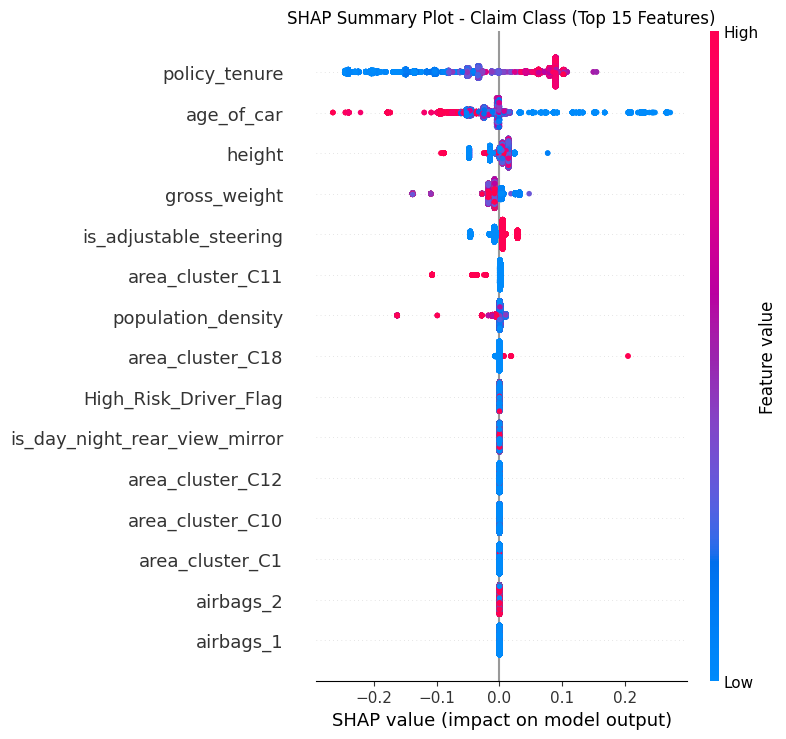

Summary plot saved to: C:\Users\kanwa\Downloads\capstone\mlflow_outputs\shap_summary_plot.png
Summary plot exists: True
CSV saved to: C:\Users\kanwa\Downloads\capstone\mlflow_outputs\shap_feature_summary.csv
CSV exists: True


,feature,mean_abs_shap,mean_signed_shap,value_shap_corr,direction
0,policy_tenure,0.09639,-0.01666,0.89123,Increases claim risk
1,age_of_car,0.03900,-0.00615,-0.46941,Decreases claim risk
2,height,0.01316,-0.00101,0.33300,Increases claim risk
3,gross_weight,0.01314,-0.00814,-0.35724,Decreases claim risk
4,is_adjustable_steering,0.01247,-0.00076,0.71421,Increases claim risk
5,area_cluster_C11,0.00257,-0.00021,-0.87452,Decreases claim risk
6,population_density,0.00226,-0.00051,-0.25790,Decreases claim risk
7,area_cluster_C18,0.00052,-0.00040,0.36553,Increases claim risk
8,area_cluster_C8,0.00000,0.00000,0.00000,Neutral (not used by model)
9,area_cluster_C22,0.00000,0.00000,0.00000,Neutral (not used by model)


In [49]:
# ==============================
# SHAP Explainability - Step 3
# Summary plot + feature-level summary table (CSV)
# ==============================

# 1. SHAP summary plot (top 15 features), saved to OUT_DIR
plt.figure()
shap.summary_plot(
    shap_values_class1,
    X_explain,
    feature_names=list(X_explain.columns),
    max_display=15,
    show=False
)
plt.title("SHAP Summary Plot - Claim Class (Top 15 Features)")
plt.tight_layout()

summary_plot_path = OUT_DIR / "shap_summary_plot.png"
plt.savefig(summary_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 2. Feature-level summary table
X_vals = X_explain.reset_index(drop=True)
shap_df = pd.DataFrame(shap_values_class1, columns=X_explain.columns)

def value_shap_corr(col):
    x = X_vals[col].astype(float)
    s = shap_df[col]
    if x.nunique() < 2 or s.nunique() < 2:   # unused feature or constant SHAP
        return 0.0
    return float(np.corrcoef(x, s)[0, 1])

feature_summary = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": np.abs(shap_values_class1).mean(axis=0),
    "mean_signed_shap": shap_values_class1.mean(axis=0),
    "value_shap_corr": [value_shap_corr(c) for c in X_explain.columns],
})

# Direction: do HIGH values of the feature push predicted claim risk up or down?
feature_summary["direction"] = np.where(
    feature_summary["mean_abs_shap"] < 1e-6, "Neutral (not used by model)",
    np.where(feature_summary["value_shap_corr"] > 0, "Increases claim risk",
             "Decreases claim risk")
)

feature_summary = (
    feature_summary
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

# 3. Export to CSV
csv_path = OUT_DIR / "shap_feature_summary.csv"
feature_summary.to_csv(csv_path, index=False)

# 4. Verify
print("Summary plot saved to:", summary_plot_path.resolve())
print("Summary plot exists:", summary_plot_path.exists())
print("CSV saved to:", csv_path.resolve())
print("CSV exists:", csv_path.exists())
display(feature_summary.head(15).round(5))

### SHAP Feature Importance Analysis

- `policy_tenure` was the most influential feature, with the highest mean absolute SHAP value of **0.09639**, followed by `age_of_car` (0.03900).
- `policy_tenure`, `height`, and `is_adjustable_steering` showed positive correlations between feature values and SHAP contributions, indicating an overall tendency toward increased claim risk.
- `age_of_car`, `gross_weight`, `area_cluster_C11`, and `population_density` showed negative correlations, indicating an overall tendency toward decreased claim risk.
- Features such as `area_cluster_C8`, `area_cluster_C22`, and `area_cluster_C21` had zero mean absolute SHAP values, indicating no meaningful contribution to predictions in this analysis.
- Overall, the model relied primarily on `policy_tenure` and `age_of_car`; SHAP directions represent model associations, not causal relationships.

- Policy id is needed so loading the original dataset in this notebook.

In [60]:
df_raw = pd.read_csv(r"dataset.csv")

In [61]:
df_raw.head(5)

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


In [52]:
# Compare the row counts and order of the original dataset with the cleaned dataset
assert len(df_raw) == len(df), "Row counts differ - cleaning removed rows"
assert (df_raw["is_claim"].values == df["is_claim"].values).all(), "Row order differs"

In [53]:
policy_id = df_raw["policy_id"].iloc[X_test2.index].values

In [54]:
policy_id

array(['ID38216', 'ID03598', 'ID32005', ..., 'ID06151', 'ID44772',
       'ID29782'], dtype=object)

##### Grouping and exporting final predictions

- Percentile-based cut points instead of fixed thresholds, because class_weight='balanced' shifts the predicted-probability scale.

- The tuned Decision Tree outputs a small set of distinct probabilities, so the 40th/75th/90th percentile cut points collide. Risk bands are therefore assigned using percentile ranks (40/75/90) with a seeded random tie-break, which preserves the intended band sizes

In [55]:
claim_probability = tree_prob
predicted_class = tree_pred
labels = ["Low", "Medium", "High", "Very High"]

# Keep the percentile cut points for reference and documentation
p40, p75, p90 = np.percentile(claim_probability, [40, 75, 90])
print(f"Cut points -> P40: {p40:.4f}, P75: {p75:.4f}, P90: {p90:.4f}")

# Percentile rank with a seeded random tie-break
prob_s = pd.Series(claim_probability)
pct_rank = (
    prob_s.sample(frac=1, random_state=42)      # shuffle so ties are broken randomly
          .rank(method="first", pct=True)
          .sort_index()                          # restore original row order
)

risk_level = pd.cut(
    pct_rank,
    bins=[0, 0.40, 0.75, 0.90, 1.0],
    labels=labels,
    include_lowest=True
).values

print(pd.Series(risk_level).value_counts(normalize=True).reindex(labels).round(3))

Cut points -> P40: 0.4781, P75: 0.6026, P90: 0.6026
Low          0.40
Medium       0.35
High         0.15
Very High    0.10
Name: proportion, dtype: float64


In [56]:
print("Distinct probabilities:", len(np.unique(claim_probability)))
print("P40, P75, P90:", np.percentile(claim_probability, [40, 75, 90]))
print(pd.Series(claim_probability).value_counts(normalize=True).head(5).round(3))

Distinct probabilities: 16
P40, P75, P90: [0.4781088 0.6025659 0.6025659]
0.602566    0.312
0.224222    0.132
0.478109    0.120
0.326280    0.101
0.502556    0.091
Name: proportion, dtype: float64


##### Prediction_output

In [57]:
# Create the final prediction output DataFrame
prediction_output = pd.DataFrame({
    "policy_id": policy_id,
    "actual_outcome": np.asarray(y_test2),
    "predicted_class": predicted_class,
    "claim_probability": claim_probability,
    "risk_level": risk_level
})

assert len(prediction_output) == len(X_test2)
prediction_output.head()

,policy_id,actual_outcome,predicted_class,claim_probability,risk_level
0,ID38216,0,1,0.602566,Medium
1,ID03598,0,0,0.224222,Low
2,ID32005,0,0,0.344511,Low
3,ID20541,0,1,0.602566,Medium
4,ID55339,0,0,0.224222,Low


##### Monotonicity check

In [58]:
claim_rates = (
    prediction_output
    .groupby("risk_level", observed=True)["actual_outcome"]
    .mean()
    .reindex(["Low", "Medium", "High", "Very High"])
)

print("Actual claim rate by risk level:")
for level, rate in claim_rates.items():
    print(f"  {level}: {rate:.4f}")

is_monotonic = bool((claim_rates.diff().dropna() > 0).all())
print("\nMonotonic increase confirmed:", is_monotonic)
if is_monotonic:
    print("Claim rate rises Low < Medium < High < Very High.")
else:
    print("WARNING: claim rate does not increase strictly across all bands.")

Actual claim rate by risk level:
  Low: 0.0363
  Medium: 0.0668
  High: 0.0899
  Very High: 0.1263

Monotonic increase confirmed: True
Claim rate rises Low < Medium < High < Very High.


In [59]:
# Save the prediction output to CSV
prediction_output.to_csv("prediction_output.csv", index=False)

check = pd.read_csv("prediction_output.csv")
print("Columns:", check.columns.tolist())
print("Shape:", check.shape)

Columns: ['policy_id', 'actual_outcome', 'predicted_class', 'claim_probability', 'risk_level']
Shape: (11719, 5)
